In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

MOVEMENT_DIR = Path(
    r"C:\Users\Sheel\OneDrive\Documents\Default Project\data\pads-parkinsons-disease-smartwatch-dataset-1.0.0\pads-parkinsons-disease-smartwatch-dataset-1.0.0\preprocessed\movement"
)

file_list = pd.read_csv(MOVEMENT_DIR.parent / "file_list.csv")

tasks = [
    "Relaxed1", "Relaxed2", "RelaxedTask1", "RelaxedTask2",
    "StretchHold", "HoldWeight", "DrinkGlas", "CrossArms",
    "TouchNose", "Entrainment1", "Entrainment2",
]
wrists = ["LeftWrist", "RightWrist"]
sensors = ["Accelerometer", "Gyroscope"]
axes = ["X", "Y", "Z"]
channels = [f"{t}_{w}_{s}_{a}" for t in tasks for w in wrists for s in sensors for a in axes]

print(len(channels), "channels")

132 channels


In [2]:
bin_files = sorted(MOVEMENT_DIR.glob("*_ml.bin"))
ids = np.array([int(f.name.split("_")[0]) for f in bin_files])
movement = np.stack([np.fromfile(f, dtype=np.float32).reshape(len(channels), -1) for f in bin_files])
print("movement:", movement.shape, movement.dtype)

movement: (469, 132, 976) float32


In [3]:
groups = {
    "Multiple Sclerosis": [17, 36, 44, 98, 142, 195, 225, 301, 421, 432, 438],
    "Healthy Controls": [52, 193, 1, 46, 455, 254, 389, 204, 45, 108, 449],
    "Essential Tremors": [100, 200, 278, 72, 143, 104, 112, 126, 423, 124, 66],
    "Atypical Parkinsonism": [397, 64, 238, 304, 114, 291, 110, 168, 32, 15, 18],
    "Parkinson's": [38, 307, 286, 299, 175, 115, 4, 119, 252, 237, 71],
}
id_to_group = {pid: g for g, pids in groups.items() for pid in pids}

mask = np.isin(ids, list(id_to_group))
mov = movement[mask]
pids = ids[mask]

channel_df = pd.DataFrame({
    "channel": channels,
    "task": [c.split("_")[0] for c in channels],
    "wrist": [c.split("_")[1] for c in channels],
    "sensor": [c.split("_")[2] for c in channels],
    "axis": [c.split("_")[3] for c in channels],
})

acc_means, gyro_means, jerk_means, acc_stds = [], [], [], []
for (task, wrist), grp in channel_df.groupby(["task", "wrist"]):
    acc = mov[:, grp.index[grp["sensor"] == "Accelerometer"].tolist(), :]
    gyro = mov[:, grp.index[grp["sensor"] == "Gyroscope"].tolist(), :]
    acc_norm = np.linalg.norm(acc, axis=1)
    gyro_norm = np.linalg.norm(gyro, axis=1)
    jerk = np.diff(acc_norm, axis=1)
    acc_means.append(acc_norm.mean(axis=1))
    gyro_means.append(gyro_norm.mean(axis=1))
    jerk_means.append(jerk.mean(axis=1))
    acc_stds.append(acc_norm.std(axis=1))

df = pd.DataFrame({
    "Acceleration Norm": np.mean(acc_means, axis=0),
    "Gyroscope Norm": np.mean(gyro_means, axis=0),
    "Jerk": np.mean(jerk_means, axis=0),
    "Acceleration Norm SD": np.mean(acc_stds, axis=0),
})
df["group"] = [id_to_group[p] for p in pids]
print(df.shape)
print(df.groupby("group").size())

(55, 5)
group
Atypical Parkinsonism    11
Essential Tremors        11
Healthy Controls         11
Multiple Sclerosis       11
Parkinson's              11
dtype: int64


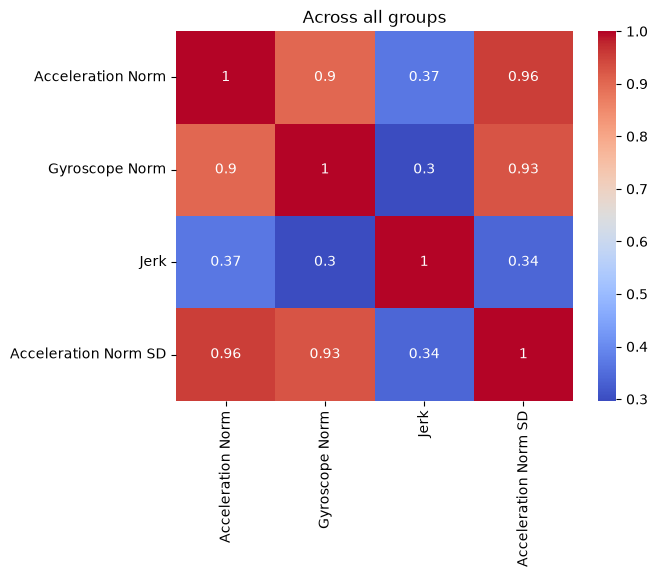

In [4]:
sns.heatmap(df.drop(columns=["group"]).corr(), annot=True, cmap="coolwarm")
plt.title("Across all groups")
plt.show()

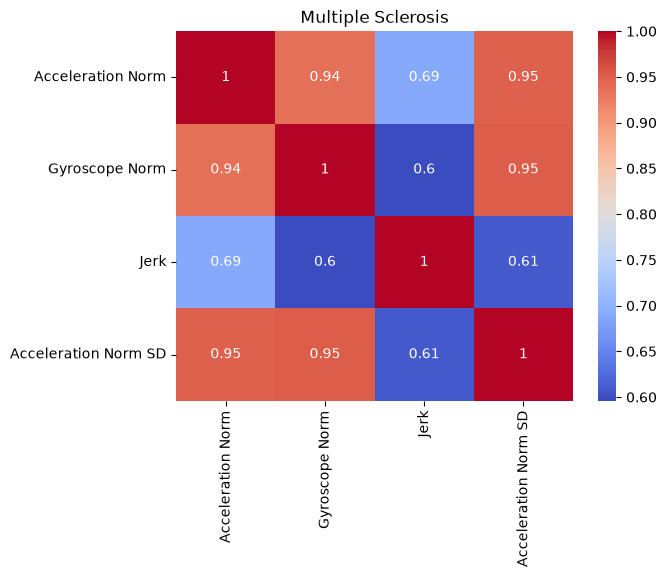

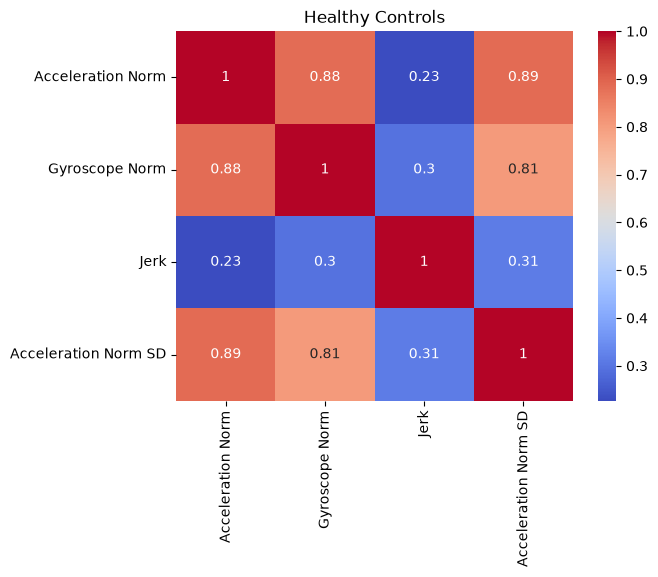

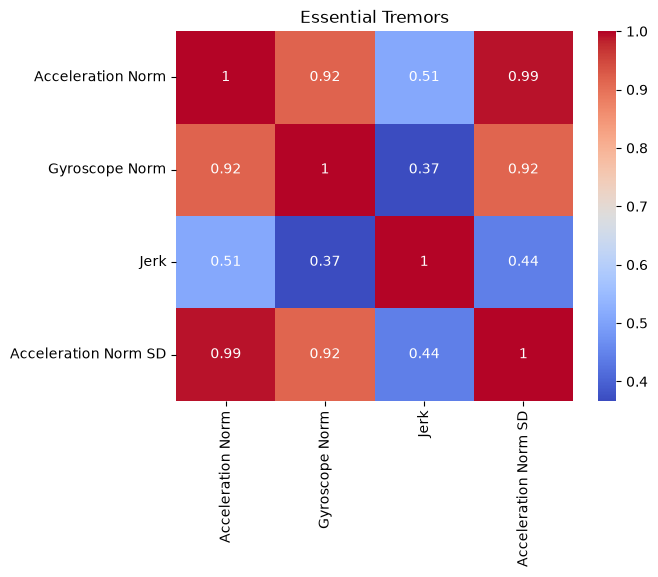

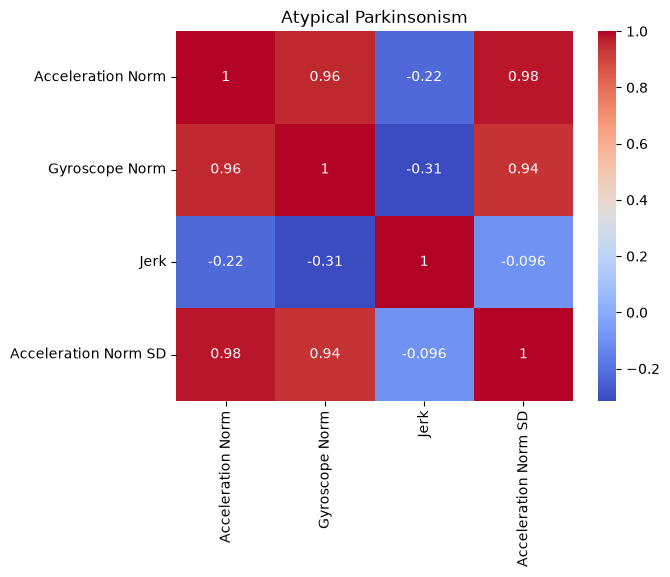

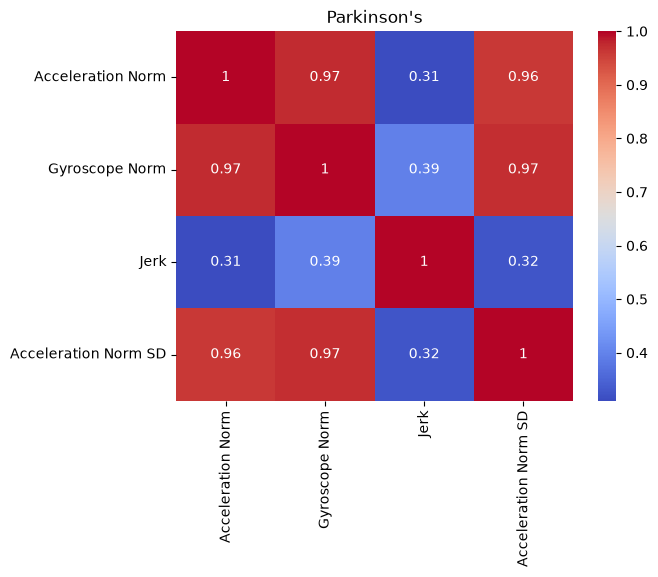

In [5]:
for g in groups:
    sub = df[df["group"] == g].drop(columns=["group"])
    sns.heatmap(sub.corr(), annot=True, cmap="coolwarm")
    plt.title(g)
    plt.show()